# 11 · Does the landlord explain the 100-meter inequality?
**Know Before You Rent · Team BUTA**

The project's central question: *do nearby residential buildings experience different rates of housing problems?* And if they do, **is the landlord the reason?**

**Design:**
1. Take every pair of residential buildings (3+ apartments) **within 100 m** of each other. Both buildings share the block, the weather, the city services and the neighborhood.
2. Split the pairs into **same landlord** and **different landlords**, using the portfolios built in notebook 07.
3. **Fair version:** also require the two buildings to be similar, with the same era and the same size band.
4. If the landlord matters, same-landlord neighbors should be **more alike** than different-landlord neighbors.

Code: `src/landlord_neighbors.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import features_housing as F, landlord_neighbors as LN
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.3f}".format)
inp = F.load_inputs()
universe = F.building_universe(inp["pluto"], inp["landlords"])
A = F.neighbor_matrix(universe)
snap = pd.read_parquet(str(F.FEATURES_FILE).format(year=2025))   # history 2023-24, outcomes 2025
assert (snap["bbl"].to_numpy() == universe["bbl"].to_numpy()).all()

pairs = LN.neighbor_pairs(universe, A)
rates = LN.building_rates(snap)
gaps = LN.pair_gaps(pairs, rates)
registered = pairs["both_registered"]
fair = registered & pairs["similar_buildings"]
pd.DataFrame({"all pairs ≤100 m": [len(pairs), pairs.same_landlord.sum()],
              "both registered": [registered.sum(), pairs[registered].same_landlord.sum()],
              "+ similar buildings": [fair.sum(), pairs[fair].same_landlord.sum()]},
             index=["pairs", "of which same landlord"])

,all pairs ≤100 m,both registered,+ similar buildings
pairs,2773744,2030737,726775
of which same landlord,24498,24498,14593


## 1. Next year: when one building gets a problem, does its neighbor too?
Similar buildings within 100 m, outcomes in **2025**. Among pairs where at least one building got the problem, how often did **both** get it?

In [2]:
agree = LN.outcome_agreement(pairs, snap, fair)
agree

,same landlord: neighbor also has it,different landlord: neighbor also has it,ratio
problem,,,
heat/hot water,0.452,0.169,2.675
pests,0.303,0.102,2.977
leaks/mold,0.340,0.122,2.783
plumbing,0.325,0.117,2.771
paint/plaster,0.335,0.116,2.877
doors/windows,0.294,0.098,3.010
safety,0.124,0.040,3.087


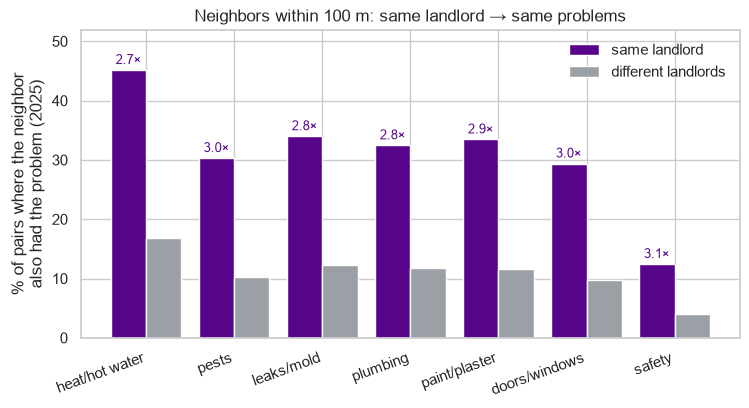

In [3]:
fig, ax = plt.subplots(figsize=(8.5, 4))
x = np.arange(len(agree))
ax.bar(x - 0.2, agree.iloc[:, 0] * 100, 0.4, color=ACCENT, label="same landlord")
ax.bar(x + 0.2, agree.iloc[:, 1] * 100, 0.4, color=MUTED, label="different landlords")
for xi, h, r in zip(x, agree.iloc[:, 0] * 100, agree["ratio"]):
    ax.text(xi - 0.2, h + 1, f"{r:.1f}×", ha="center", fontsize=9, color=ACCENT)
ax.set_ylim(0, agree.iloc[:, 0].max() * 100 * 1.15)
ax.set_xticks(x, agree.index, rotation=20, ha="right")
ax.set(ylabel="% of pairs where the neighbor\nalso had the problem (2025)",
       title="Neighbors within 100 m: same landlord → same problems")
ax.legend(frameon=False)
save(fig, "rent11a_same_landlord_cooccurrence")

## 2. How different are neighbors' problem rates?
- **Gap** = |log(1 + complaints per 100 apartments)| between the two buildings, over 2023–24. A gap of 0.69 means one building has about double the other's rate.
- Pairs where **both** buildings had zero problems are left out: they always look alike and say nothing about the landlord. The cell below shows why this matters.
- 95% intervals come from a bootstrap over pairs.

In [4]:
active = LN.at_least_one_problem(pairs, rates)
z = rates["all problems"].to_numpy() == 0
p = pairs[registered]
both_zero = z[p.i] & z[p.j]
print(f"Pairs where both buildings are problem-free: same landlord {both_zero[p.same_landlord.to_numpy()].mean():.0%}, "
      f"different landlords {both_zero[~p.same_landlord.to_numpy()].mean():.0%}")
gap_table = LN.compare(pairs, gaps, registered & active, n_boot=200)
gap_table["same landlord is … smaller"] = (1 - gap_table["same ÷ different"]).map("{:.0%}".format)
gap_table

Pairs where both buildings are problem-free: same landlord 31%, different landlords 49%


,same-landlord pairs,different-landlord pairs,gap: same landlord,gap: different landlord,same ÷ different,95% CI low,95% CI high,same landlord is … smaller
measure,,,,,,,,
all problems,16964,1027321,1.887,3.018,0.625,0.619,0.634,37%
heat/hot water,16964,1027321,1.598,2.077,0.770,0.759,0.782,23%
pests,16964,1027321,1.037,1.204,0.861,0.844,0.877,14%
leaks/mold,16964,1027321,1.174,1.412,0.831,0.814,0.847,17%
plumbing,16964,1027321,1.083,1.182,0.916,0.900,0.931,8%
paint/plaster,16964,1027321,1.002,1.101,0.911,0.897,0.928,9%
doors/windows,16964,1027321,0.953,1.070,0.891,0.872,0.906,11%
safety,16964,1027321,0.547,0.551,0.993,0.967,1.022,1%


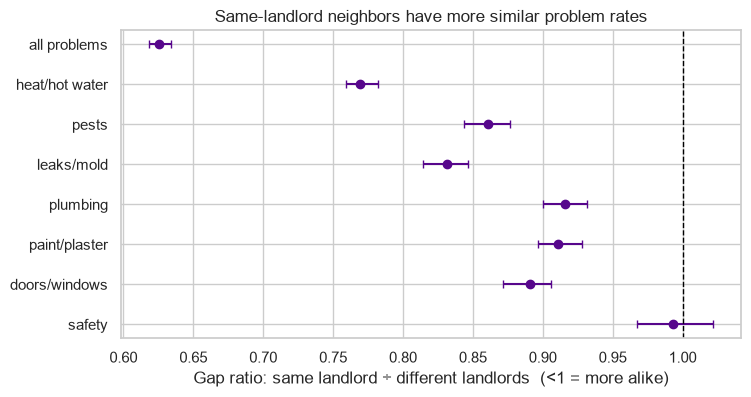

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
g = gap_table.iloc[::-1]
y = np.arange(len(g))
ax.errorbar(g["same ÷ different"], y, xerr=[g["same ÷ different"] - g["95% CI low"], g["95% CI high"] - g["same ÷ different"]],
            fmt="o", color=ACCENT, capsize=3)
ax.axvline(1, color="black", lw=1, ls="--")
ax.set_yticks(y, g.index)
ax.set(xlabel="Gap ratio: same landlord ÷ different landlords  (<1 = more alike)",
       title="Same-landlord neighbors have more similar problem rates")
save(fig, "rent11b_gap_ratio")

## 3. What this means
- **The 100-meter inequality is real, and the landlord is a large part of it.** Two buildings on the same block, sharing the same neighborhood, the same weather and the same city services, behave far more alike when one landlord runs both.
- **For the renter:** the landlord's other buildings tell you a lot about the one you're about to rent. That's why the landlord record is a feature in our model (notebook 10).

**Caveats**
- Some same-landlord pairs are parts of one complex (adjacent lots, one boiler), which naturally share problems.
- Landlords are matched by managing agent or office address, so some portfolios are approximate.
- Complaints measure *reported* problems.

The "similar buildings" filter (same era and size band) removes the simplest alternative explanation: that one landlord just owns one kind of building.